# PD calibration v2: isotonic regression + Bayesian prior adjustment

Drop-in replacement for `PD_calibration.ipynb`. It uses the same inputs (the score files written by `train_xgb.ipynb`) and does not change the model or the train / test / OOT split.

**Two steps**
1. **Isotonic regression** (Zadrozny & Elkan, 2002) fixes the *shape*: a monotone map from XGBoost score to observed default rate. Fitted on the **test (2010)** scores, so the map is not learned on rows the model was trained on.
2. **Bayesian prior adjustment** (Bohn & Stein, 2009, Ch. 4, p. 220; Elkan, 2001) fixes the *level*: shifts every PD so the average matches the **training default rate**, keeps the ranking, and never goes above 1.

    `PD* = pi_T (PD - PD*pi_S) / (pi_S - PD*pi_S + PD*pi_T - pi_S*pi_T)`

    pi_S = average isotonic PD on the calibration sample, pi_T = target default rate.

Results are compared on **OOT (2011)** against the raw scores and the original decile calibration.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from scipy.stats import binom

In [3]:
train_scores = pd.read_csv('../Model_scores/scores_train.csv')
test_scores = pd.read_csv('../Model_scores/scores_test.csv')
oot_scores = pd.read_csv('../Model_scores/scores_oot.csv')

print('rows      ', len(train_scores), len(test_scores), len(oot_scores))
print('default rate', round(train_scores['y_true'].mean(), 4), round(test_scores['y_true'].mean(), 4), round(oot_scores['y_true'].mean(), 4))

rows       475389 174229 183730
default rate 0.014 0.017 0.0116


## Settings
- `CALIB_SET`: scores the isotonic map is fitted on (test = 2010, held out from training).
- `TARGET_RATE`: the default rate the PDs are shifted to (training default rate).
- `PD_FLOOR`: Basel minimum PD of 0.03%.

In [4]:
CALIB_SET = test_scores
TARGET_RATE = train_scores['y_true'].mean()
PD_FLOOR = 0.0003
PD_CAP = 0.9999

print('Target default rate (pi_T):', round(TARGET_RATE, 4))

Target default rate (pi_T): 0.014


## Baseline: original decile calibration (Anubhav's method)
Same logic as `PD_calibration.ipynb`, but bins are assigned with `pd.cut` and open outer edges so no score is left without a bin.

In [5]:
train_scores['bins'] = pd.qcut(train_scores['y_pred'], q=10, labels=False, duplicates='drop')
score_agg = (
    train_scores.groupby('bins')
    .agg(y_true=('y_true', 'mean'),
         lower_bound=('y_pred', 'min'),
         upper_bound=('y_pred', 'max'))
    .reset_index()
)

edges = [-np.inf] + list(score_agg['upper_bound'].iloc[:-1]) + [np.inf]

def decile_pd(scores):
    bins = pd.cut(scores, bins=edges, labels=False)
    return bins.map(dict(zip(score_agg['bins'], score_agg['y_true']))).astype(float)

score_agg

,bins,y_true,lower_bound,upper_bound
0,0,0.000126,0.000131,0.001079
1,1,0.000526,0.001079,0.001776
2,2,0.000778,0.001776,0.002718
3,3,0.001494,0.002718,0.003999
4,4,0.002903,0.003999,0.005668
5,5,0.004544,0.005668,0.007836
6,6,0.007047,0.007836,0.010842
7,7,0.010455,0.010843,0.015901
8,8,0.020383,0.015901,0.028363
9,9,0.091630,0.028363,0.897082


## Step 1: isotonic regression (shape)

In [6]:
iso = IsotonicRegression(y_min=PD_FLOOR, y_max=PD_CAP, out_of_bounds='clip')
iso.fit(CALIB_SET['y_pred'], CALIB_SET['y_true'])

def isotonic_pd(scores):
    return pd.Series(iso.predict(scores), index=scores.index)

pi_S = isotonic_pd(CALIB_SET['y_pred']).mean()
print('Average isotonic PD on calibration sample (pi_S):', round(pi_S, 4))

Average isotonic PD on calibration sample (pi_S): 0.017


## Step 2: Bayesian prior adjustment (level)

In [7]:
def bayes_adjust(p, pi_s, pi_t):
    p = np.asarray(p, dtype=float)
    adjusted = pi_t * (p - p * pi_s) / (pi_s - p * pi_s + p * pi_t - pi_s * pi_t)
    return np.clip(adjusted, PD_FLOOR, PD_CAP)

def calibrated_pd(scores):
    return pd.Series(bayes_adjust(isotonic_pd(scores), pi_S, TARGET_RATE), index=scores.index)

# quick check: after the adjustment the calibration sample averages close to the target rate
print('Average PD on calibration sample after adjustment:', round(calibrated_pd(CALIB_SET['y_pred']).mean(), 4))

Average PD on calibration sample after adjustment: 0.0142


## Apply all methods

In [8]:
for df in [train_scores, test_scores, oot_scores]:
    df['pd_raw'] = df['y_pred'].clip(PD_FLOOR, PD_CAP)
    df['pd_decile'] = decile_pd(df['y_pred']).clip(PD_FLOOR, PD_CAP)
    df['pd_isotonic'] = isotonic_pd(df['y_pred'])
    df['pd_iso_bayes'] = calibrated_pd(df['y_pred'])

METHODS = ['pd_raw', 'pd_decile', 'pd_isotonic', 'pd_iso_bayes']
oot_scores[['y_true', 'y_pred'] + METHODS].head()

,y_true,y_pred,pd_raw,pd_decile,pd_isotonic,pd_iso_bayes
0,0,0.020329,0.020329,0.020383,0.030417,0.025046
1,0,0.000695,0.000695,0.000300,0.000752,0.000615
2,0,0.004424,0.004424,0.002903,0.006573,0.005388
3,0,0.001185,0.001185,0.000526,0.000866,0.000709
4,0,0.002583,0.002583,0.000778,0.002987,0.002447


## Compare on OOT (2011) and test (2010)
- **AUC**: ranking. Should be (almost) the same for every method; isotonic can add small ties.
- **Mean PD vs actual rate**: overall level.
- **Brier, log-loss**: probability accuracy, lower is better.

Note: the test set is also the isotonic fitting sample, so test results for the isotonic methods are in-sample. OOT is the fair comparison.

In [9]:
def summary(df, name):
    rows = []
    for m in METHODS:
        p = df[m].clip(1e-6, 1 - 1e-6)
        rows.append({
            'set': name,
            'method': m,
            'AUC': roc_auc_score(df['y_true'], p),
            'mean_PD': p.mean(),
            'actual_rate': df['y_true'].mean(),
            'Brier': brier_score_loss(df['y_true'], p),
            'LogLoss': log_loss(df['y_true'], p),
        })
    return pd.DataFrame(rows)

results = pd.concat([summary(test_scores, 'test_2010'), summary(oot_scores, 'oot_2011')])
results.round(5)

,set,method,AUC,mean_PD,actual_rate,Brier,LogLoss
0,test_2010,pd_raw,0.82852,0.01286,0.01703,0.01560,0.07195
1,test_2010,pd_decile,0.81965,0.01290,0.01703,0.01614,0.07509
2,test_2010,pd_isotonic,0.82994,0.01703,0.01703,0.01549,0.07077
3,test_2010,pd_iso_bayes,0.82994,0.01419,0.01703,0.01552,0.07107
0,oot_2011,pd_raw,0.84439,0.01322,0.01161,0.01081,0.05178
1,oot_2011,pd_decile,0.83298,0.01339,0.01161,0.01123,0.05429
2,oot_2011,pd_isotonic,0.84364,0.01749,0.01161,0.01089,0.05286
3,oot_2011,pd_iso_bayes,0.84364,0.01457,0.01161,0.01080,0.05199


## Calibration table on OOT (2011): predicted PD vs actual default rate by decile of score

In [10]:
def calib_table(df, n=10):
    t = df.copy()
    t['bucket'] = pd.qcut(t['y_pred'].rank(method='first'), n, labels=False) + 1
    return t.groupby('bucket').agg(
        firms=('y_true', 'size'),
        actual_rate=('y_true', 'mean'),
        pd_raw=('pd_raw', 'mean'),
        pd_decile=('pd_decile', 'mean'),
        pd_isotonic=('pd_isotonic', 'mean'),
        pd_iso_bayes=('pd_iso_bayes', 'mean'),
    )

oot_table = calib_table(oot_scores)
oot_table.round(4)

,firms,actual_rate,pd_raw,pd_decile,pd_isotonic,pd_iso_bayes
bucket,,,,,,
1,18373,0.0005,0.0007,0.0003,0.0007,0.0006
2,18373,0.0006,0.0013,0.0005,0.0013,0.0011
3,18373,0.0011,0.0021,0.0007,0.0024,0.0019
4,18373,0.0024,0.0031,0.0014,0.0044,0.0036
5,18373,0.0044,0.0044,0.0026,0.0068,0.0055
6,18373,0.0053,0.0062,0.0041,0.0099,0.0081
7,18373,0.0075,0.0086,0.0065,0.0110,0.0090
8,18373,0.0112,0.0123,0.0098,0.0189,0.0155
9,18373,0.0210,0.0202,0.0194,0.0306,0.0252


## Reliability plot on OOT (2011)
Points on the dashed line mean predicted PD equals the actual default rate.

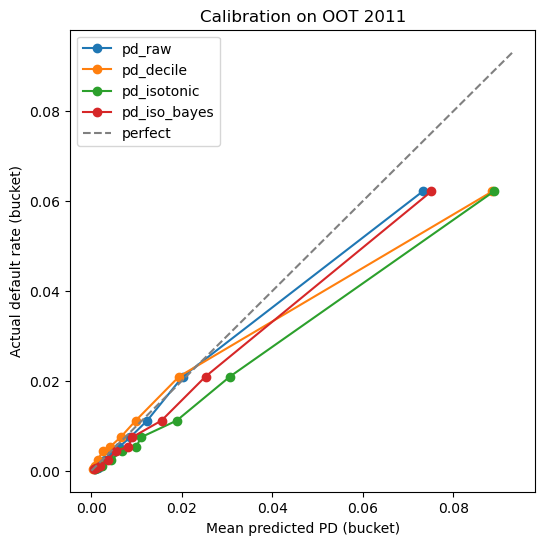

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
for m in METHODS:
    ax.plot(oot_table[m], oot_table['actual_rate'], marker='o', label=m)
top = max(oot_table[METHODS].max().max(), oot_table['actual_rate'].max()) * 1.05
ax.plot([0, top], [0, top], linestyle='--', color='grey', label='perfect')
ax.set_xlabel('Mean predicted PD (bucket)')
ax.set_ylabel('Actual default rate (bucket)')
ax.set_title('Calibration on OOT 2011')
ax.legend()
plt.show()

## Binomial test per bucket (Bohn & Stein, Ch. 7)
For each score decile on OOT 2011: if the PDs are right, the number of defaults follows a binomial with n = firms and p = mean PD.
- `expected_def` = firms x mean PD
- `low_95`, `high_95` = 95% range of default counts under that PD
- `p_value` = two-sided binomial p-value; `pass` = actual defaults inside the 95% range

This test assumes defaults are independent. Defaults in the same year are correlated (common economy), which widens the true range, so a few failures in a bad year are expected (Bohn & Stein, Ch. 7, error bounds with correlation).

In [12]:
def binomial_test(df, pd_col, n=10):
    t = df.copy()
    t['bucket'] = pd.qcut(t['y_pred'].rank(method='first'), n, labels=False) + 1
    rows = []
    for b, g in t.groupby('bucket'):
        firms = len(g)
        defaults = int(g['y_true'].sum())
        p = g[pd_col].mean()
        low, high = binom.ppf(0.025, firms, p), binom.ppf(0.975, firms, p)
        p_lower = binom.cdf(defaults, firms, p)
        p_upper = binom.sf(defaults - 1, firms, p)
        rows.append({
            'bucket': b, 'firms': firms, 'mean_PD': p,
            'expected_def': firms * p, 'actual_def': defaults,
            'low_95': low, 'high_95': high,
            'p_value': min(1.0, 2 * min(p_lower, p_upper)),
            'pass': low <= defaults <= high,
        })
    return pd.DataFrame(rows).set_index('bucket')

for m in METHODS:
    bt = binomial_test(oot_scores, m)
    print(f'{m}: {bt["pass"].sum()} of {len(bt)} buckets pass')

binomial_test(oot_scores, 'pd_iso_bayes').round(4)

pd_raw: 7 of 10 buckets pass
pd_decile: 6 of 10 buckets pass
pd_isotonic: 1 of 10 buckets pass
pd_iso_bayes: 1 of 10 buckets pass


,firms,mean_PD,expected_def,actual_def,low_95,high_95,p_value,pass
bucket,,,,,,,,
1,18373,0.0006,10.3198,9,5.0,17.0,0.8371,True
2,18373,0.0011,20.0398,11,12.0,29.0,0.0418,False
3,18373,0.0019,35.5795,21,24.0,48.0,0.0117,False
4,18373,0.0036,66.1767,45,51.0,83.0,0.0074,False
5,18373,0.0055,101.7515,81,83.0,122.0,0.0386,False
6,18373,0.0081,149.3983,98,126.0,174.0,0.0000,False
7,18373,0.0090,165.7466,137,141.0,191.0,0.0240,False
8,18373,0.0155,284.6764,205,252.0,318.0,0.0000,False
9,18373,0.0252,463.4620,385,422.0,506.0,0.0002,False


## Calibration by segment on OOT 2011
Mean PD vs actual default rate by sector and legal structure, for the main method. Segments with very few firms are noisy, so only segments with at least 200 firms are shown.

In [13]:
SEGMENT_COLS = [c for c in ['sector_category', 'legal_structure_category'] if c in oot_scores.columns]
MIN_FIRMS = 200

for col in SEGMENT_COLS:
    seg = oot_scores.groupby(col).agg(
        firms=('y_true', 'size'),
        actual_rate=('y_true', 'mean'),
        pd_decile=('pd_decile', 'mean'),
        pd_iso_bayes=('pd_iso_bayes', 'mean'),
    )
    seg = seg[seg['firms'] >= MIN_FIRMS].sort_values('firms', ascending=False)
    seg['gap_iso_bayes'] = seg['pd_iso_bayes'] - seg['actual_rate']
    print(col)
    display(seg.round(4))

sector_category


,firms,actual_rate,pd_decile,pd_iso_bayes,gap_iso_bayes
sector_category,,,,,
68.0,36168,0.0077,0.0074,0.0090,0.0013
41.0,25479,0.0131,0.0146,0.0161,0.0030
46.0,20618,0.0145,0.0159,0.0167,0.0022
25.0,8318,0.0103,0.0118,0.0137,0.0033
47.0,7529,0.0151,0.0154,0.0168,0.0017
28.0,5714,0.0105,0.0136,0.0148,0.0043
43.0,5600,0.0157,0.0172,0.0178,0.0020
45.0,4326,0.0155,0.0157,0.0179,0.0024
70.0,4122,0.0124,0.0197,0.0198,0.0074


legal_structure_category


,firms,actual_rate,pd_decile,pd_iso_bayes,gap_iso_bayes
legal_structure_category,,,,,
SRL,133083,0.0111,0.0129,0.0142,0.0031
SRU,28358,0.0170,0.0193,0.0200,0.0030
SPA,17882,0.0082,0.0083,0.0100,0.0018
SAU,4363,0.0076,0.0095,0.0104,0.0029


## Calibration checks summary (OOT 2011)
One row per method:
- `level_gap`: mean PD minus actual default rate (closer to 0 is better)
- `buckets_pass`: buckets passing the binomial test
- `Brier`, `LogLoss`: lower is better
- `AUC_change`: AUC minus raw AUC (should be about 0)
- `monotone`: bucket PDs never go down as score rises

In [14]:
raw_auc = roc_auc_score(oot_scores['y_true'], oot_scores['pd_raw'])
checks = []
for m in METHODS:
    p = oot_scores[m].clip(1e-6, 1 - 1e-6)
    table_pd = calib_table(oot_scores)[m]
    checks.append({
        'method': m,
        'level_gap': p.mean() - oot_scores['y_true'].mean(),
        'buckets_pass': f"{binomial_test(oot_scores, m)['pass'].sum()}/10",
        'Brier': brier_score_loss(oot_scores['y_true'], p),
        'LogLoss': log_loss(oot_scores['y_true'], p),
        'AUC_change': roc_auc_score(oot_scores['y_true'], p) - raw_auc,
        'monotone': bool((table_pd.diff().dropna() >= 0).all()),
    })
pd.DataFrame(checks).set_index('method').round(5)

,level_gap,buckets_pass,Brier,LogLoss,AUC_change,monotone
method,,,,,,
pd_raw,0.00161,7/10,0.01081,0.05178,0.00000,True
pd_decile,0.00178,6/10,0.01123,0.05429,-0.01142,True
pd_isotonic,0.00588,1/10,0.01089,0.05286,-0.00075,True
pd_iso_bayes,0.00296,1/10,0.01080,0.05199,-0.00075,True


## Isotonic map (score to PD) before and after the level adjustment

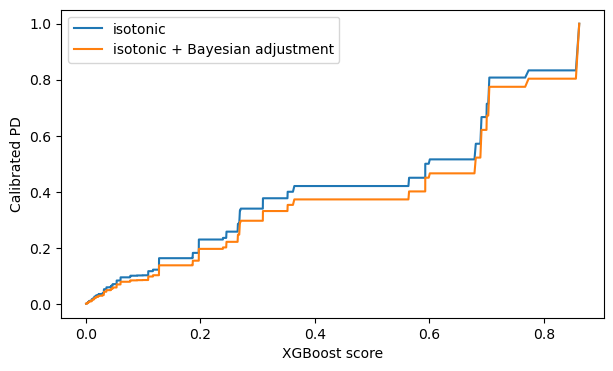

In [15]:
grid = pd.Series(np.sort(CALIB_SET['y_pred'].unique()))
plt.figure(figsize=(7, 4))
plt.plot(grid, isotonic_pd(grid), label='isotonic')
plt.plot(grid, calibrated_pd(grid), label='isotonic + Bayesian adjustment')
plt.xlabel('XGBoost score')
plt.ylabel('Calibrated PD')
plt.legend()
plt.show()

## Save calibrated scores

In [ ]:
oot_scores.to_csv('../Model_scores/scores_oot_calibration2.csv', index=False)
test_scores.to_csv('../Model_scores/scores_test_calibration2.csv', index=False)

**References**
- Zadrozny, B., & Elkan, C. (2002). Transforming classifier scores into accurate multiclass probability estimates. *KDD '02*, 694–699.
- Bohn, J. R., & Stein, R. M. (2009). *Active Credit Portfolio Management in Practice*. Wiley. Ch. 4, "Estimating the Prior Probabilities", pp. 220–221.
- Elkan, C. (2001). The foundations of cost-sensitive learning. *IJCAI '01*, 973–978.